# Ranh giới quyết định của mô hình đơn lẻ và mô hình tổ hợp (mục 9.2.2)

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Cùng dữ liệu với phần 3 của codes/09_single_vs_ensemble.ipynb

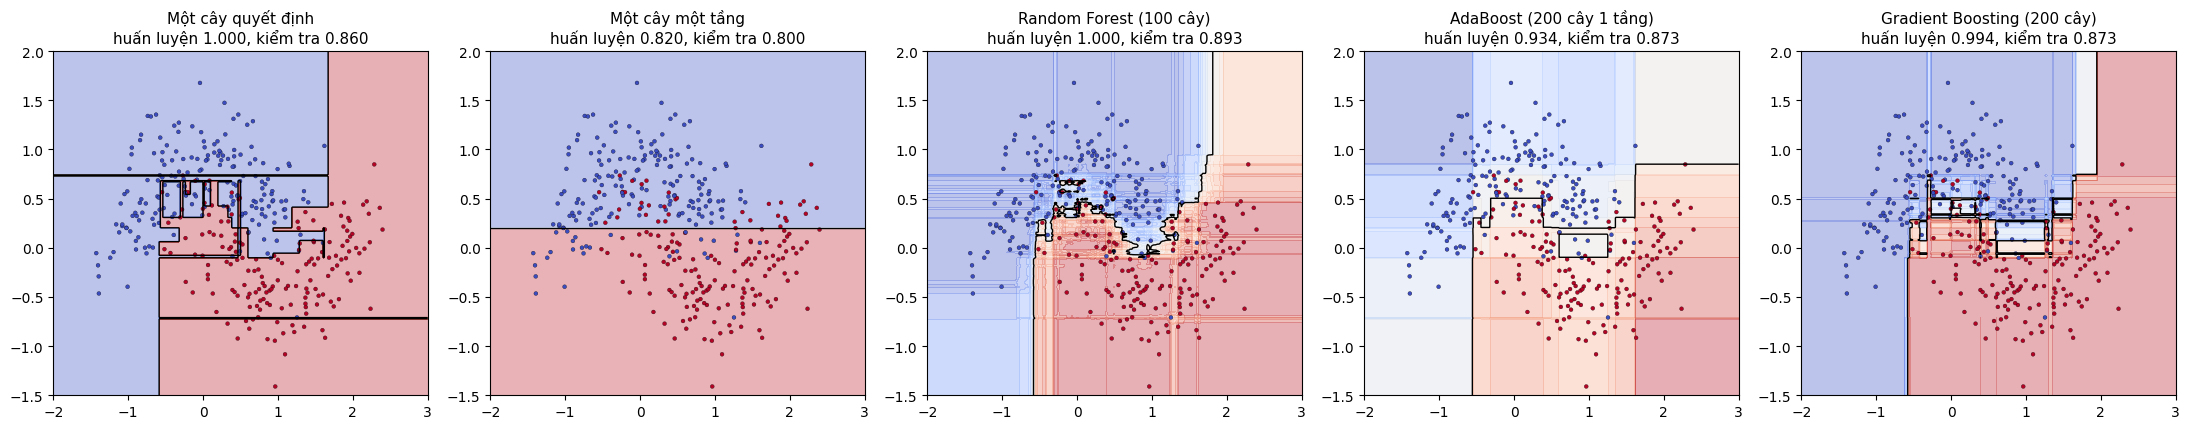

In [2]:
X, y = make_moons(n_samples=500, noise=0.3, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

models = [('Một cây quyết định', DecisionTreeClassifier(random_state=0)),
          ('Một cây một tầng', DecisionTreeClassifier(max_depth=1)),
          ('Random Forest (100 cây)', RandomForestClassifier(n_estimators=100, random_state=0)),
          ('AdaBoost (200 cây 1 tầng)', AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=200, random_state=0)),
          ('Gradient Boosting (200 cây)', GradientBoostingClassifier(n_estimators=200, max_depth=2, random_state=0))]

xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
fig, axes = plt.subplots(1, 5, figsize=(22, 4.4))
for ax, (name, model) in zip(axes, models):
    model.fit(X_train, y_train)
    zz = model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=20, cmap='coolwarm', alpha=0.35)
    ax.contour(xx, yy, zz, levels=[0.5], colors='k', linewidths=1)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', s=8, edgecolors='k', linewidths=0.2)
    ax.set_title('%s\nhuấn luyện %.3f, kiểm tra %.3f' % (name, model.score(X_train, y_train), model.score(X_test, y_test)),
                 fontsize=11)
fig.tight_layout()
fig.savefig(IMAGES / 'ensemble_boundaries.png', dpi=150)